In [31]:
from __future__ import annotations

import json
import math
from pathlib import Path
from typing import Any

import pandas as pd

RUN_METRIC_COLUMNS = ["Pass%", "Step", "PStep", "FStep", "Cost", "PCost", "FCost"]
HARNESS_KEY_MAP = {
    "Step": "average_steps",
    "PStep": "average_steps_passed",
    "FStep": "average_steps_failed",
    "Cost": "average_cost",
    "PCost": "average_cost_passed",
    "FCost": "average_cost_failed",
}

from IPython.display import display

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)


def discover_run_dirs(experiment_dir: str | Path) -> list[Path]:
    path = Path(experiment_dir).expanduser().resolve()
    if not path.is_dir():
        raise FileNotFoundError(f"Experiment directory not found: {path}")
    return sorted(child for child in path.iterdir() if child.is_dir())


def _format_experiment_label(experiment_dir: Path, results_root: str | Path | None = None) -> str:
    if results_root is None:
        return experiment_dir.name
    root_path = Path(results_root).expanduser().resolve()
    try:
        return experiment_dir.resolve().relative_to(root_path).as_posix()
    except ValueError:
        return experiment_dir.name


def _to_float(value: Any) -> float:
    if value is None:
        return math.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        return math.nan


def _to_int(value: Any) -> int:
    if value is None:
        return 0
    try:
        return int(float(value))
    except (TypeError, ValueError):
        return 0


def load_run_data(run_dir: str | Path, results_root: str | Path | None = None):
    run_path = Path(run_dir).expanduser().resolve()
    eval_results_path = run_path / "eval_results.json"
    if not eval_results_path.is_file():
        raise FileNotFoundError(f"Missing eval_results.json: {eval_results_path}")

    with eval_results_path.open("r") as f:
        payload = json.load(f)

    if not isinstance(payload, dict):
        raise ValueError(f"Expected JSON object in {eval_results_path}")
    if len(payload) != 1:
        raise ValueError(
            f"Expected exactly one agent entry in {eval_results_path}, found {len(payload)}"
        )

    agent_name, agent_payload = next(iter(payload.items()))
    if not isinstance(agent_payload, dict):
        raise ValueError(f"Expected object payload for agent {agent_name!r} in {eval_results_path}")

    instance_results = agent_payload.get("instance_results")
    instance_metrics = agent_payload.get("instance_metrics")
    harness_metrics = agent_payload.get("harness_metrics", {})

    if not isinstance(instance_results, dict):
        raise ValueError(f"Invalid instance_results for run {run_path}")
    if instance_metrics is None:
        instance_metrics = {}
    if not isinstance(instance_metrics, dict):
        raise ValueError(f"Invalid instance_metrics for run {run_path}")
    if harness_metrics is None:
        harness_metrics = {}
    if not isinstance(harness_metrics, dict):
        raise ValueError(f"Invalid harness_metrics for run {run_path}")

    normalized_results = {str(instance_id): bool(passed) for instance_id, passed in instance_results.items()}
    passed_instances = sum(normalized_results.values())
    total_instances = len(normalized_results)
    failed_instances = total_instances - passed_instances

    warnings = []
    run_row = {
        "experiment": _format_experiment_label(run_path.parent, results_root=results_root),
        "experiment_dir": str(run_path.parent),
        "run_name": run_path.name,
        "run_dir": str(run_path),
        "agent_name": str(agent_name),
        "total_instances": total_instances,
        "passed_instances": passed_instances,
        "failed_instances": failed_instances,
        "Pass%": (100.0 * passed_instances / total_instances) if total_instances else math.nan,
    }

    for metric_name, harness_key in HARNESS_KEY_MAP.items():
        run_row[metric_name] = _to_float(harness_metrics.get(harness_key))
        if harness_key not in harness_metrics:
            warnings.append(
                f"Run {run_path} is missing harness_metrics.{harness_key}; {metric_name} will be NaN"
            )

    instance_rows = []
    if not instance_metrics:
        warnings.append(f"Run {run_path} is missing instance_metrics; instance-level plots will skip this run")
    else:
        missing_metric_ids = sorted(set(normalized_results) - set(instance_metrics))
        if missing_metric_ids:
            warnings.append(
                f"Run {run_path} is missing instance_metrics for {len(missing_metric_ids)} instance(s)"
            )

        for instance_id, passed in normalized_results.items():
            item = instance_metrics.get(instance_id)
            if not isinstance(item, dict):
                continue
            instance_rows.append(
                {
                    "experiment": run_row["experiment"],
                    "experiment_dir": run_row["experiment_dir"],
                    "run_name": run_row["run_name"],
                    "run_dir": run_row["run_dir"],
                    "agent_name": run_row["agent_name"],
                    "instance_id": instance_id,
                    "passed": bool(item.get("passed", passed)),
                    "steps": _to_int(item.get("steps")),
                    "cost": _to_float(item.get("cost")),
                    "input_tokens": _to_int(item.get("input_tokens")),
                    "output_tokens": _to_int(item.get("output_tokens")),
                    "cache_tokens": _to_int(item.get("cache_tokens")),
                    "has_traj_cost": bool(item.get("has_traj_cost", False)),
                }
            )

    return run_row, instance_rows, warnings


def build_experiment_frames(experiment_dirs: list[str | Path], results_root: str | Path | None = None):
    warnings = []
    summary_rows = []
    run_rows = []
    instance_rows = []

    for experiment_dir in experiment_dirs:
        experiment_path = Path(experiment_dir).expanduser().resolve()
        experiment_label = _format_experiment_label(experiment_path, results_root=results_root)

        try:
            run_dirs = discover_run_dirs(experiment_path)
        except FileNotFoundError as exc:
            warnings.append(str(exc))
            summary_row = {
                "experiment": experiment_label,
                "experiment_dir": str(experiment_path),
                "valid_runs": 0,
                "skipped_runs": 0,
                "total_instance_samples": 0,
            }
            for column in RUN_METRIC_COLUMNS:
                summary_row[column] = math.nan
            summary_rows.append(summary_row)
            continue

        experiment_run_rows = []
        experiment_instance_rows = []
        skipped_runs = 0

        for run_dir in run_dirs:
            try:
                run_row, run_instance_rows, run_warnings = load_run_data(
                    run_dir, results_root=results_root
                )
            except (FileNotFoundError, ValueError, json.JSONDecodeError) as exc:
                skipped_runs += 1
                warnings.append(f"Skipped {run_dir}: {exc}")
                continue

            experiment_run_rows.append(run_row)
            experiment_instance_rows.extend(run_instance_rows)
            run_rows.append(run_row)
            instance_rows.extend(run_instance_rows)
            warnings.extend(run_warnings)

        summary_row = {
            "experiment": experiment_label,
            "experiment_dir": str(experiment_path),
            "valid_runs": len(experiment_run_rows),
            "skipped_runs": skipped_runs,
            "total_instance_samples": len(experiment_instance_rows),
        }

        if experiment_run_rows:
            experiment_runs_df = pd.DataFrame(experiment_run_rows)
            for column in RUN_METRIC_COLUMNS:
                summary_row[column] = float(experiment_runs_df[column].mean())
        else:
            for column in RUN_METRIC_COLUMNS:
                summary_row[column] = math.nan

        summary_rows.append(summary_row)

    summary_df = pd.DataFrame(summary_rows)
    runs_df = pd.DataFrame(run_rows)
    instances_df = pd.DataFrame(instance_rows)

    if not summary_df.empty:
        summary_df = summary_df[
            ["experiment", "experiment_dir", "valid_runs", "skipped_runs", "total_instance_samples"]
            + RUN_METRIC_COLUMNS
        ].sort_values("experiment", ignore_index=True)

    if not runs_df.empty:
        runs_df = runs_df[
            [
                "experiment",
                "experiment_dir",
                "run_name",
                "run_dir",
                "agent_name",
                "total_instances",
                "passed_instances",
                "failed_instances",
            ]
            + RUN_METRIC_COLUMNS
        ].sort_values(["experiment", "run_name"], ignore_index=True)
    else:
        runs_df = pd.DataFrame(
            columns=[
                "experiment",
                "experiment_dir",
                "run_name",
                "run_dir",
                "agent_name",
                "total_instances",
                "passed_instances",
                "failed_instances",
            ]
            + RUN_METRIC_COLUMNS
        )

    if not instances_df.empty:
        instances_df = instances_df.sort_values(["experiment", "run_name", "instance_id"], ignore_index=True)
    else:
        instances_df = pd.DataFrame(
            columns=[
                "experiment",
                "experiment_dir",
                "run_name",
                "run_dir",
                "agent_name",
                "instance_id",
                "passed",
                "steps",
                "cost",
                "input_tokens",
                "output_tokens",
                "cache_tokens",
                "has_traj_cost",
            ]
        )

    return summary_df, runs_df, instances_df, warnings



def _plot_instance_metric_group(instances_df: pd.DataFrame, value_column: str, metric_specs: list[tuple[str, pd.Series]], title: str) -> None:
    plot_frames = []
    for metric_name, mask in metric_specs:
        subset = instances_df.loc[mask, ["experiment", value_column]].copy()
        subset["metric"] = metric_name
        subset = subset.rename(columns={value_column: "value"})
        plot_frames.append(subset)

    plot_df = pd.concat(plot_frames, ignore_index=True)
    metrics = [metric_name for metric_name, _ in metric_specs]
    fig, axes = plt.subplots(1, len(metrics), figsize=(7 * len(metrics), 6), constrained_layout=True)
    if len(metrics) == 1:
        axes = [axes]

    for ax, metric_name in zip(axes, metrics):
        metric_df = plot_df.loc[plot_df["metric"] == metric_name]
        if metric_df.empty:
            ax.text(0.5, 0.5, f"No instance-level data for {metric_name}", ha="center", va="center")
            ax.set_axis_off()
            continue

        sns.violinplot(data=metric_df, x="experiment", y="value", inner="quart", cut=0, ax=ax)
        ax.set_title(metric_name)
        ax.set_xlabel("Experiment")
        ax.set_ylabel(metric_name)
        ax.tick_params(axis="x", rotation=25)

    fig.suptitle(title, fontsize=18)
    plt.show()


In [32]:
RESULTS_ROOT = Path("/nvme2/zzr/mem-comp-26-leason/harness/results")

SELECTED_EXPERIMENT_DIRS = [
    RESULTS_ROOT / "qwencoder" / "newbaseline",
    RESULTS_ROOT / "qwencoder" / "newexternalmem",
    RESULTS_ROOT / "qwencoder" / "externalmem-k5",
    RESULTS_ROOT / "qwencoder" / "onlyexp",
    RESULTS_ROOT / "qwencoder" / "onlyfact",
]

SELECTED_EXPERIMENT_DIRS


[PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/newbaseline'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/newexternalmem'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/externalmem-k5'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/onlyexp'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/onlyfact')]

In [33]:
summary_df, runs_df, instances_df, warnings = build_experiment_frames(
    SELECTED_EXPERIMENT_DIRS,
    results_root=RESULTS_ROOT,
)

print(f"Experiments loaded: {len(summary_df)}")
print(f"Valid runs: {len(runs_df)}")
print(f"Instance samples: {len(instances_df)}")

if warnings:
    print("Warnings:")
    for warning in warnings:
        print(f"- {warning}")
else:
    print("Warnings: none")


Experiments loaded: 5
Valid runs: 23
Instance samples: 4600
Warnings: none


In [34]:
summary_view = summary_df.copy()
for column in RUN_METRIC_COLUMNS:
    if column in summary_view:
        summary_view[column] = summary_view[column].round(4)

display(summary_view)


,experiment,experiment_dir,valid_runs,skipped_runs,total_instance_samples,Pass%,Step,PStep,FStep,Cost,PCost,FCost
0,qwencoder/externalmem-k5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,3,0,600,43.8333,155.3233,150.7093,158.9410,0.9412,0.8579,1.0065
1,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,42.7000,165.7520,161.3674,168.8739,0.9173,0.8467,0.9692
2,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,47.7000,148.7260,143.8266,153.0876,0.9660,0.8867,1.0374
3,qwencoder/onlyexp,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,44.1000,154.3230,148.2901,159.0628,0.9561,0.8672,1.0261
4,qwencoder/onlyfact,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,43.1000,152.5730,148.1435,155.9303,0.9409,0.8649,0.9988


In [35]:
runs_view = runs_df.copy()
for column in RUN_METRIC_COLUMNS:
    if column in runs_view:
        runs_view[column] = runs_view[column].round(4)

display(runs_view)


,experiment,experiment_dir,run_name,run_dir,agent_name,total_instances,passed_instances,failed_instances,Pass%,Step,PStep,FStep,Cost,PCost,FCost
0,qwencoder/externalmem-k5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run1,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-k5-20260313001002-530c,200,93,107,46.5,154.330,149.1935,158.7944,0.9263,0.8444,0.9975
1,qwencoder/externalmem-k5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run2,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-k5-20260313001011-79ba,200,88,112,44.0,157.630,153.8977,160.5625,0.9576,0.8700,1.0264
2,qwencoder/externalmem-k5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run3,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-k5-20260313001022-7a79,200,82,118,41.0,154.010,149.0366,157.4661,0.9397,0.8594,0.9955
3,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run1,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260306020913-e591,200,85,115,42.5,165.895,161.8588,168.8783,0.9198,0.8442,0.9757
4,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run2,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260306020940-b4b9,200,95,105,47.5,167.390,163.6947,170.7333,0.9334,0.8604,0.9994
5,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run3,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260306021026-3f37,200,75,125,37.5,164.850,158.1733,168.8560,0.9206,0.8427,0.9674
6,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run4,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260312012438-775b,200,82,118,41.0,164.935,157.8659,169.8475,0.9075,0.8076,0.9770
7,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260312012430-b9dd,200,90,110,45.0,165.690,165.2444,166.0545,0.9050,0.8785,0.9267
8,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run1,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260306201945-4bc3,200,84,116,42.0,143.820,136.1905,149.3448,0.9239,0.8115,1.0053
9,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run2,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260306201956-010b,200,98,102,49.0,150.970,146.1633,155.5882,0.9908,0.9046,1.0735


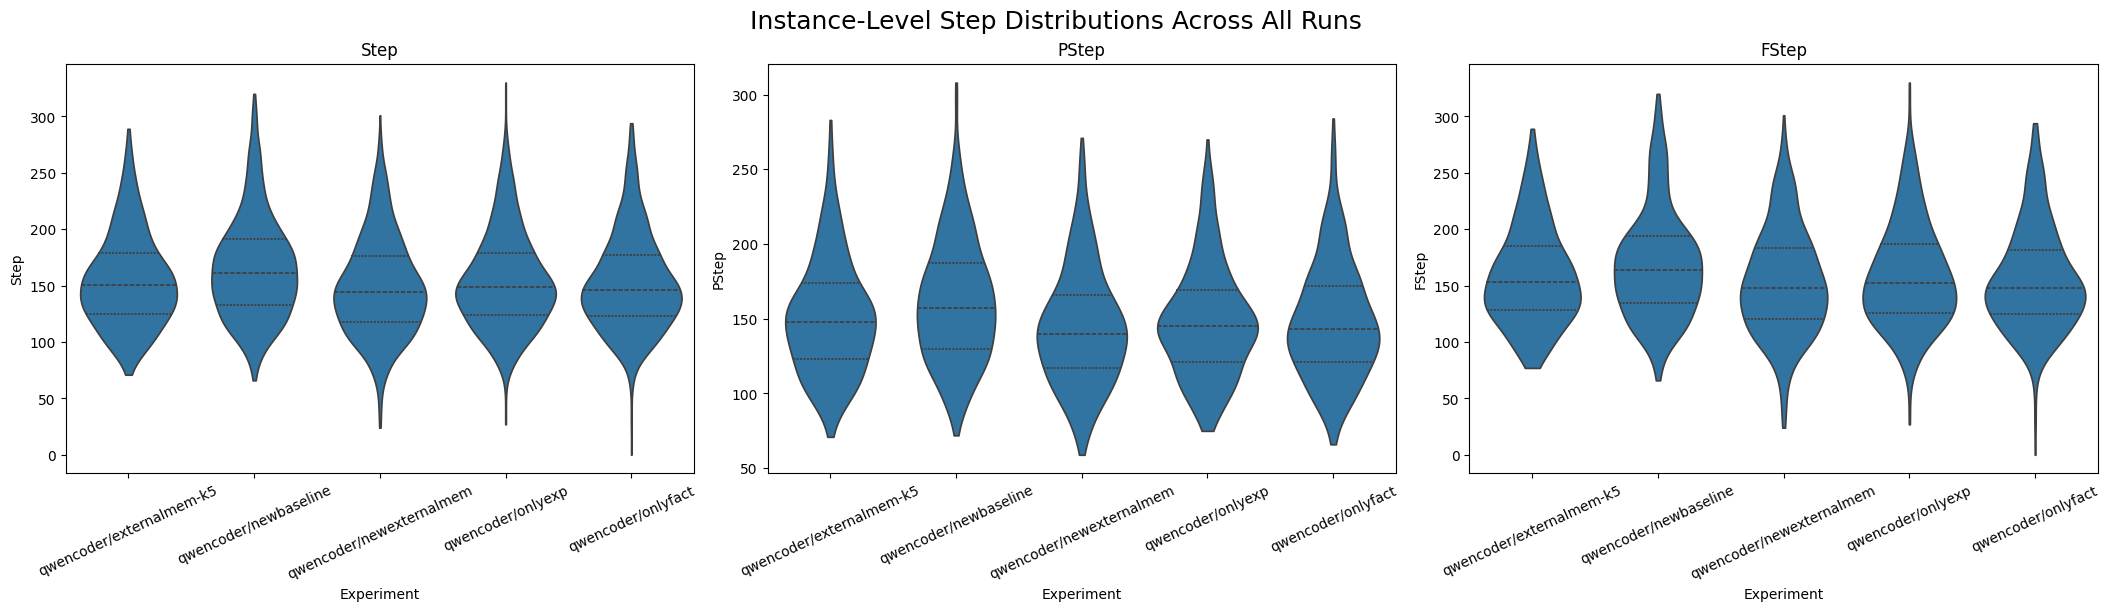

In [36]:
_plot_instance_metric_group(
    instances_df,
    value_column="steps",
    metric_specs=[
        ("Step", instances_df.index == instances_df.index),
        ("PStep", instances_df["passed"]),
        ("FStep", ~instances_df["passed"]),
    ],
    title="Instance-Level Step Distributions Across All Runs",
)


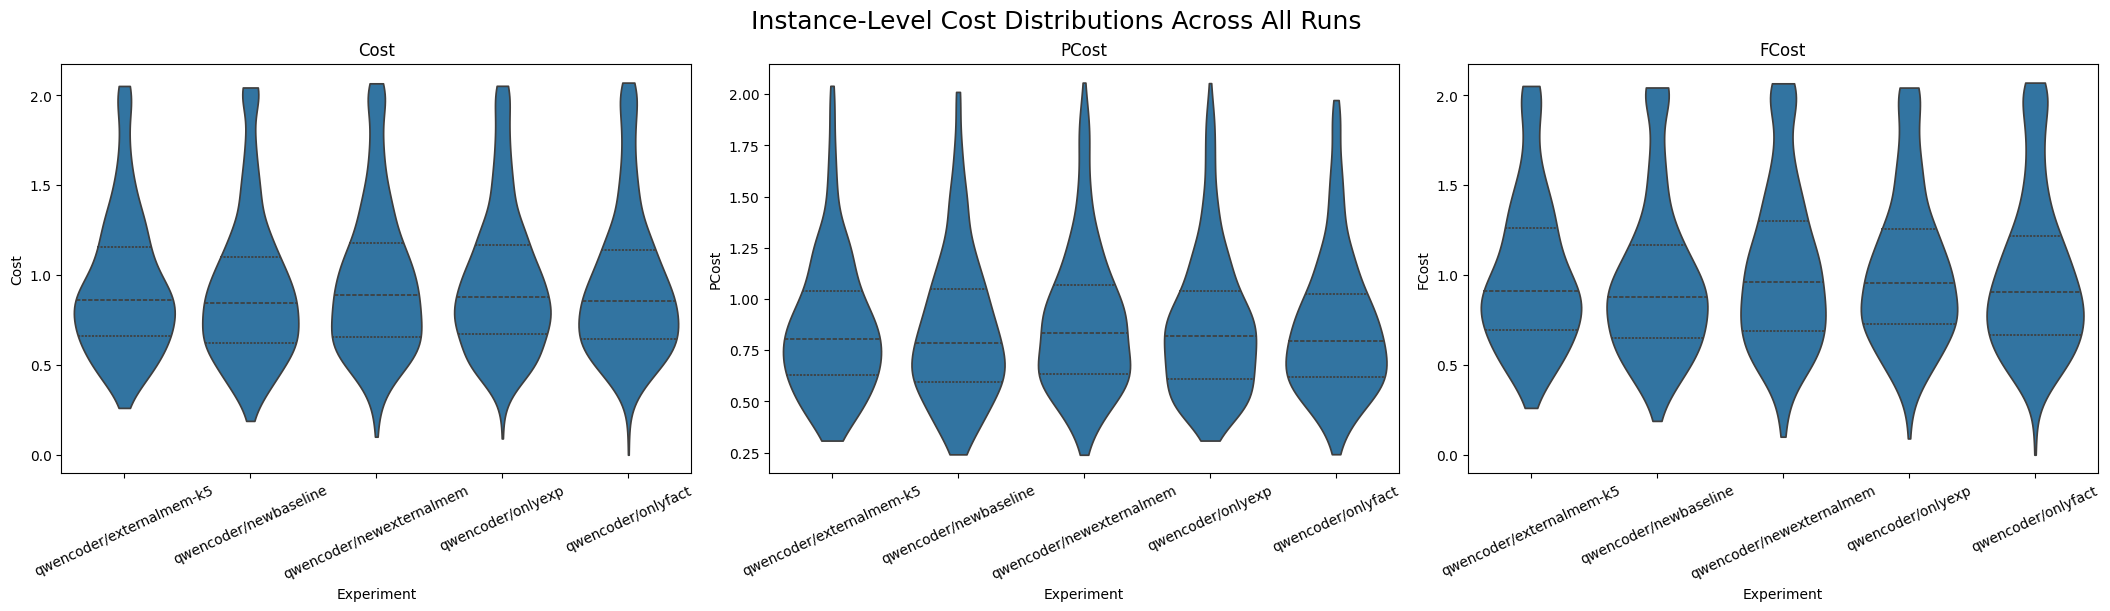

In [37]:
_plot_instance_metric_group(
    instances_df,
    value_column="cost",
    metric_specs=[
        ("Cost", instances_df.index == instances_df.index),
        ("PCost", instances_df["passed"]),
        ("FCost", ~instances_df["passed"]),
    ],
    title="Instance-Level Cost Distributions Across All Runs",
)


In [ ]:
import re

BASELINE_EXPERIMENT = "qwencoder/newbaseline"
INSTANCE_BUCKET_SIZE = 5
EXPERIMENT_ORDER = [
    _format_experiment_label(Path(experiment_dir), results_root=RESULTS_ROOT)
    for experiment_dir in SELECTED_EXPERIMENT_DIRS
]


def _extract_project_name(instance_id: str) -> str:
    if not instance_id.startswith("instance_"):
        raise ValueError(f"Unexpected instance id format: {instance_id}")

    name_parts = instance_id.removeprefix("instance_").split("-")
    while len(name_parts) > 1 and re.fullmatch(r"v?(?:[0-9a-f]{7,}|nan)", name_parts[-1]):
        name_parts.pop()
    return "-".join(name_parts)


canonical_projects_path = RESULTS_ROOT.parent / "projects_full.json"
with canonical_projects_path.open("r") as f:
    canonical_projects = json.load(f)

PROJECT_INSTANCE_COUNT = len(canonical_projects[0])
POSITION_BUCKET_ORDER = [
    f"{bucket_start}-{min(bucket_start + INSTANCE_BUCKET_SIZE - 1, PROJECT_INSTANCE_COUNT - 1)}"
    for bucket_start in range(0, PROJECT_INSTANCE_COUNT, INSTANCE_BUCKET_SIZE)
]

project_rows = []
for project_index, project_instances in enumerate(canonical_projects):
    if len(project_instances) != PROJECT_INSTANCE_COUNT:
        raise ValueError(
            f"Expected {PROJECT_INSTANCE_COUNT} instances for project group {project_index}, found {len(project_instances)}"
        )

    project_name = _extract_project_name(project_instances[0])
    for project_pos, instance_id in enumerate(project_instances):
        bucket_start = (project_pos // INSTANCE_BUCKET_SIZE) * INSTANCE_BUCKET_SIZE
        bucket_end = min(bucket_start + INSTANCE_BUCKET_SIZE - 1, PROJECT_INSTANCE_COUNT - 1)
        project_rows.append(
            {
                "instance_id": instance_id,
                "project": project_name,
                "project_index": project_index,
                "project_pos": project_pos,
                "instance_order": project_pos,
                "sequence_bucket": f"{bucket_start}-{bucket_end}",
            }
        )

project_map_df = pd.DataFrame(project_rows)
project_order = (
    project_map_df[["project_index", "project"]]
    .drop_duplicates()
    .sort_values("project_index")
    ["project"]
    .tolist()
)

annotated_instances_df = instances_df.merge(
    project_map_df,
    on="instance_id",
    how="left",
    validate="many_to_one",
)
missing_project_rows = int(annotated_instances_df["project"].isna().sum())
assert missing_project_rows == 0, f"Found {missing_project_rows} unmapped instance rows"

annotated_instances_df["project"] = pd.Categorical(
    annotated_instances_df["project"],
    categories=project_order,
    ordered=True,
)
annotated_instances_df["sequence_bucket"] = pd.Categorical(
    annotated_instances_df["sequence_bucket"],
    categories=POSITION_BUCKET_ORDER,
    ordered=True,
)

print(f"Baseline experiment: {BASELINE_EXPERIMENT}")
print(f"Canonical project order: {canonical_projects_path}")
print(f"Annotated instance rows: {len(annotated_instances_df)}")
display(project_map_df.groupby(["project_index", "project"], as_index=False).size())


,instance_id,project,project_index,project_pos,instance_order,sequence_bucket
0,instance_qutebrowser__qutebrowser-77c355799570...,qutebrowser__qutebrowser,0,0,0,0-4
1,instance_qutebrowser__qutebrowser-deeb15d6f009...,qutebrowser__qutebrowser,0,1,1,0-4
2,instance_qutebrowser__qutebrowser-21b426b6a20e...,qutebrowser__qutebrowser,0,2,2,0-4
3,instance_qutebrowser__qutebrowser-5fdc83e5da62...,qutebrowser__qutebrowser,0,3,3,0-4
4,instance_qutebrowser__qutebrowser-ff1c025ad321...,qutebrowser__qutebrowser,0,4,4,0-4


Baseline experiment: qwencoder/newbaseline
Canonical project order: /nvme2/zzr/mem-comp-26-leason/harness/projects_full.json
Annotated instance rows: 4600


,project_index,project,size
0,0,qutebrowser__qutebrowser,25
1,1,NodeBB__NodeBB,25
2,2,ansible__ansible,25
3,3,navidrome__navidrome,25
4,4,internetarchive__openlibrary,25
5,5,element-hq__element-web,25
6,6,protonmail__webclients,25
7,7,future-architect__vuls,25


experiment,qwencoder/newbaseline,qwencoder/newexternalmem,qwencoder/externalmem-k5,qwencoder/onlyexp,qwencoder/onlyfact
project,,,,,
qutebrowser__qutebrowser,45.6,60.0,56.00,53.6,49.6
NodeBB__NodeBB,44.8,47.2,40.00,39.2,40.0
ansible__ansible,48.8,52.0,44.00,48.8,46.4
navidrome__navidrome,33.6,43.2,37.33,37.6,30.4
internetarchive__openlibrary,40.8,42.4,44.00,41.6,50.4
element-hq__element-web,33.6,45.6,46.67,40.0,42.4
protonmail__webclients,46.4,44.8,42.67,46.4,44.0
future-architect__vuls,48.0,46.4,40.00,45.6,41.6


,project,experiment,pass_rate_pct,baseline_pass_rate_pct,delta_pp
0,qutebrowser__qutebrowser,qwencoder/newbaseline,45.60,45.6,0.00
1,qutebrowser__qutebrowser,qwencoder/newexternalmem,60.00,45.6,14.40
2,qutebrowser__qutebrowser,qwencoder/externalmem-k5,56.00,45.6,10.40
3,qutebrowser__qutebrowser,qwencoder/onlyexp,53.60,45.6,8.00
4,qutebrowser__qutebrowser,qwencoder/onlyfact,49.60,45.6,4.00
5,NodeBB__NodeBB,qwencoder/newbaseline,44.80,44.8,0.00
6,NodeBB__NodeBB,qwencoder/newexternalmem,47.20,44.8,2.40
7,NodeBB__NodeBB,qwencoder/externalmem-k5,40.00,44.8,-4.80
8,NodeBB__NodeBB,qwencoder/onlyexp,39.20,44.8,-5.60
9,NodeBB__NodeBB,qwencoder/onlyfact,40.00,44.8,-4.80


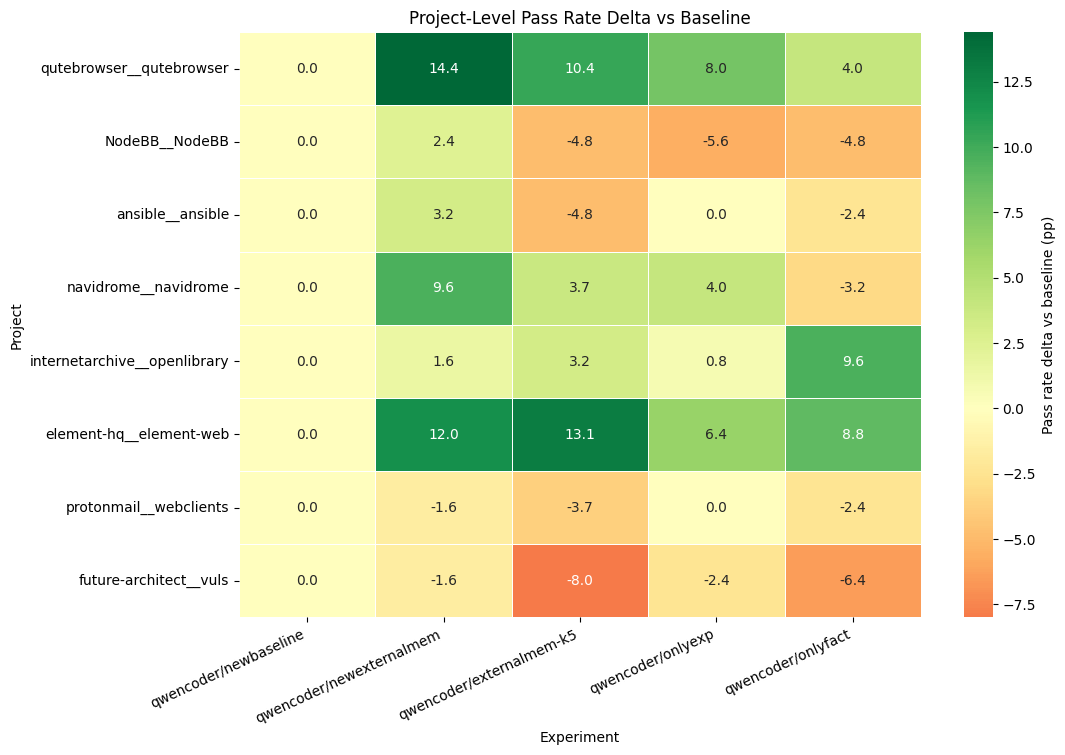

In [39]:
project_pass_rate_df = (
    annotated_instances_df.groupby(["experiment", "project_index", "project"], observed=True, as_index=False)["passed"]
    .mean()
)
project_pass_rate_df["pass_rate_pct"] = project_pass_rate_df["passed"] * 100

project_baseline_df = project_pass_rate_df.loc[
    project_pass_rate_df["experiment"] == BASELINE_EXPERIMENT,
    ["project", "pass_rate_pct"],
].rename(columns={"pass_rate_pct": "baseline_pass_rate_pct"})

project_comparison_df = project_pass_rate_df.merge(project_baseline_df, on="project", how="left")
project_comparison_df["delta_pp"] = (
    project_comparison_df["pass_rate_pct"] - project_comparison_df["baseline_pass_rate_pct"]
)
project_comparison_df["experiment"] = pd.Categorical(
    project_comparison_df["experiment"],
    categories=EXPERIMENT_ORDER,
    ordered=True,
)
project_comparison_df = project_comparison_df.sort_values(
    ["project_index", "experiment"],
    ignore_index=True,
)

expected_project_rows = len(project_order) * len(EXPERIMENT_ORDER)
assert len(project_comparison_df) == expected_project_rows, (
    f"Expected {expected_project_rows} project rows, found {len(project_comparison_df)}"
)
baseline_project_delta = project_comparison_df.loc[
    project_comparison_df["experiment"] == BASELINE_EXPERIMENT, "delta_pp"
]
assert baseline_project_delta.fillna(0).eq(0).all(), "Baseline project deltas must be 0"

project_pass_rate_pivot = project_comparison_df.pivot(
    index="project",
    columns="experiment",
    values="pass_rate_pct",
).reindex(index=project_order, columns=EXPERIMENT_ORDER)
project_delta_pivot = project_comparison_df.pivot(
    index="project",
    columns="experiment",
    values="delta_pp",
).reindex(index=project_order, columns=EXPERIMENT_ORDER)

display(project_pass_rate_pivot.round(2))
display(
    project_comparison_df[["project", "experiment", "pass_rate_pct", "baseline_pass_rate_pct", "delta_pp"]]
    .round(2)
)

fig, ax = plt.subplots(figsize=(1.8 * len(EXPERIMENT_ORDER) + 2, 0.7 * len(project_order) + 2))
sns.heatmap(
    project_delta_pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Pass rate delta vs baseline (pp)"},
    ax=ax,
)
ax.set_title("Project-Level Pass Rate Delta vs Baseline")
ax.set_xlabel("Experiment")
ax.set_ylabel("Project")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.show()


experiment,qwencoder/newbaseline,qwencoder/newexternalmem,qwencoder/externalmem-k5,qwencoder/onlyexp,qwencoder/onlyfact
sequence_bucket,,,,,
0-4,41.0,46.0,50.00,46.5,47.5
5-9,39.5,46.5,39.17,41.0,40.5
10-14,41.0,45.0,40.83,42.0,39.5
15-19,39.5,44.0,34.17,40.5,38.0
20-24,52.5,57.0,55.00,50.5,50.0


,sequence_bucket,experiment,pass_rate_pct,baseline_pass_rate_pct,delta_pp
0,0-4,qwencoder/newbaseline,41.00,41.0,0.00
1,0-4,qwencoder/newexternalmem,46.00,41.0,5.00
2,0-4,qwencoder/externalmem-k5,50.00,41.0,9.00
3,0-4,qwencoder/onlyexp,46.50,41.0,5.50
4,0-4,qwencoder/onlyfact,47.50,41.0,6.50
5,5-9,qwencoder/newbaseline,39.50,39.5,0.00
6,5-9,qwencoder/newexternalmem,46.50,39.5,7.00
7,5-9,qwencoder/externalmem-k5,39.17,39.5,-0.33
8,5-9,qwencoder/onlyexp,41.00,39.5,1.50
9,5-9,qwencoder/onlyfact,40.50,39.5,1.00


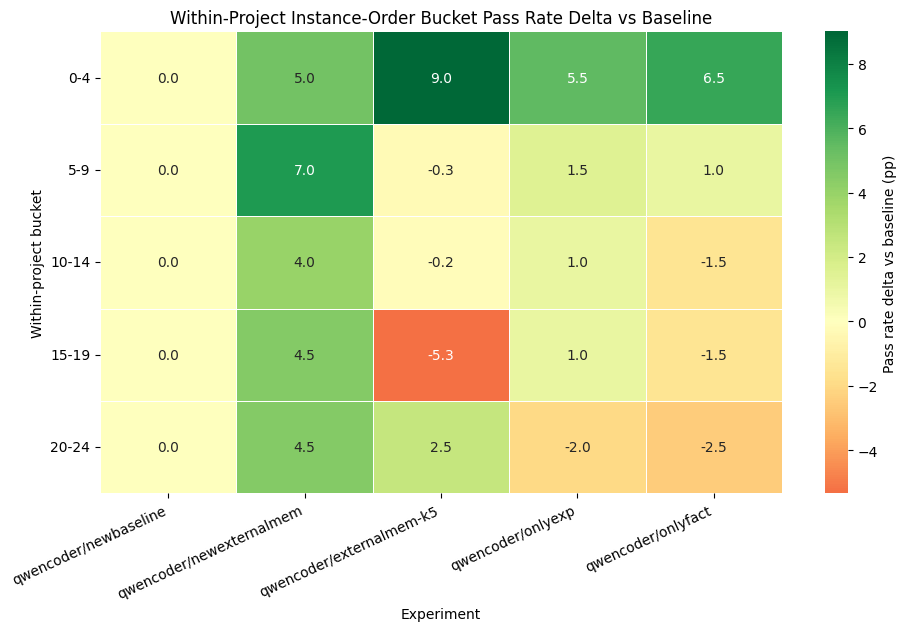

In [40]:
project_bucket_pass_rate_df = (
    annotated_instances_df.groupby(
        ["experiment", "project_index", "project", "sequence_bucket"],
        observed=True,
        as_index=False,
    )["passed"]
    .mean()
)
bucket_pass_rate_df = (
    project_bucket_pass_rate_df.groupby(
        ["experiment", "sequence_bucket"],
        observed=True,
        as_index=False,
    )["passed"]
    .mean()
)
bucket_pass_rate_df["pass_rate_pct"] = bucket_pass_rate_df["passed"] * 100

bucket_baseline_df = bucket_pass_rate_df.loc[
    bucket_pass_rate_df["experiment"] == BASELINE_EXPERIMENT,
    ["sequence_bucket", "pass_rate_pct"],
].rename(columns={"pass_rate_pct": "baseline_pass_rate_pct"})

bucket_comparison_df = bucket_pass_rate_df.merge(
    bucket_baseline_df,
    on=["sequence_bucket"],
    how="left",
)
bucket_comparison_df["delta_pp"] = (
    bucket_comparison_df["pass_rate_pct"] - bucket_comparison_df["baseline_pass_rate_pct"]
)
bucket_comparison_df["experiment"] = pd.Categorical(
    bucket_comparison_df["experiment"],
    categories=EXPERIMENT_ORDER,
    ordered=True,
)
bucket_comparison_df["sequence_bucket"] = pd.Categorical(
    bucket_comparison_df["sequence_bucket"],
    categories=POSITION_BUCKET_ORDER,
    ordered=True,
)
bucket_comparison_df = bucket_comparison_df.sort_values(
    ["sequence_bucket", "experiment"],
    ignore_index=True,
)

expected_bucket_rows = len(POSITION_BUCKET_ORDER) * len(EXPERIMENT_ORDER)
assert len(bucket_comparison_df) == expected_bucket_rows, (
    f"Expected {expected_bucket_rows} bucket rows, found {len(bucket_comparison_df)}"
)
baseline_bucket_delta = bucket_comparison_df.loc[
    bucket_comparison_df["experiment"] == BASELINE_EXPERIMENT, "delta_pp"
]
assert baseline_bucket_delta.fillna(0).eq(0).all(), "Baseline bucket deltas must be 0"
assert list(bucket_comparison_df["sequence_bucket"].cat.categories) == POSITION_BUCKET_ORDER

bucket_pass_rate_pivot = bucket_comparison_df.pivot(
    index="sequence_bucket",
    columns="experiment",
    values="pass_rate_pct",
).reindex(index=POSITION_BUCKET_ORDER, columns=EXPERIMENT_ORDER)
bucket_delta_pivot = bucket_comparison_df.pivot(
    index="sequence_bucket",
    columns="experiment",
    values="delta_pp",
).reindex(index=POSITION_BUCKET_ORDER, columns=EXPERIMENT_ORDER)

display(bucket_pass_rate_pivot.round(2))
display(
    bucket_comparison_df[["sequence_bucket", "experiment", "pass_rate_pct", "baseline_pass_rate_pct", "delta_pp"]]
    .round(2)
)

fig, ax = plt.subplots(figsize=(1.8 * len(EXPERIMENT_ORDER) + 2, 0.8 * len(POSITION_BUCKET_ORDER) + 2))
sns.heatmap(
    bucket_delta_pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.4,
    cbar_kws={"label": "Pass rate delta vs baseline (pp)"},
    ax=ax,
)
ax.set_title("Within-Project Instance-Order Bucket Pass Rate Delta vs Baseline")
ax.set_xlabel("Experiment")
ax.set_ylabel("Within-project bucket")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.show()
